In [1]:
suppressMessages({
library(ggplot2)
library(dplyr)
library(stringr)
library(scales)
library(viridis)
library(ggrepel)
library(ggpubr)
library(GenomicRanges)
library(TxDb.Hsapiens.UCSC.hg38.knownGene)
library(org.Hs.eg.db)
library(dplyr)
library(Biostrings)
library(BSgenome.Hsapiens.UCSC.hg38)
library(cowplot)
library(ggrastr)
library(biomaRt)
library(patchwork)  
library(reshape2)
})

### Reading in T7 mapping data
Defining a function to load in count data from T7 mapping experiments using a targeted forward primer

In [2]:
read_t7 <- function(sample, suffix, base_path = "./") {

    t7.path <- paste0(base_path, "t7_counts/", sample, suffix)

    t7 <- read.table(t7.path, header=TRUE, sep="\t")
    t7 <- t7[t7$location != "None-0",]
    
    colnames(t7) <- c("read_id","n_reads","n_umis")
    
    t7$barcode <- sub("^.*?-.*?-", "", t7$read_id)
    t7$location <- sub("-[^-]+$", "", t7$read_id)
    t7
    }

Reading in the T7 mapping data from K562 cells transfected 3 times and profiled three days after the third transfection. Aligned read processing was done with notebook *02_parse_bam_to_counts_v2.ipynb*, specifically the *process_reads_relaxed_cigar()* function:

In [3]:
r1_t7 <- read_t7("t7_R1_S1", ".counts.unique.filtered.relaxed-cigar.tsv","../../top-100_K562-3N-3d-T7/")
r2_t7 <- read_t7("t7_R2_S2", ".counts.unique.filtered.relaxed-cigar.tsv","../../top-100_K562-3N-3d-T7/")
r3_t7 <- read_t7("t7_R3_S3", ".counts.unique.filtered.relaxed-cigar.tsv","../../top-100_K562-3N-3d-T7/")

n1_t7 <- read_t7("t7_N1_S4", ".counts.unique.filtered.relaxed-cigar.tsv","../../top-100_K562-3N-3d-T7/")
n2_t7 <- read_t7("t7_N2_S5", ".counts.unique.filtered.relaxed-cigar.tsv","../../top-100_K562-3N-3d-T7/")
n3_t7 <- read_t7("t7_N3_S6", ".counts.unique.filtered.relaxed-cigar.tsv","../../top-100_K562-3N-3d-T7/")

### Loading and formatting a dataframe oligo information
Reading in a dataframe called "pELS.gRNAs" that contains information on the CREs that were targeted (e.g. genomic coordinates, spacers used, etc.) as well as a dataframe with the ordered oligo sequences called "oligos":

In [4]:
pELS.gRNAs <- read.csv("../../top-100_K562-3N-3d-T7/gRNA-pairs_K562-intronic-pELS.csv", header = TRUE, stringsAsFactors = FALSE)

pELS.gRNAs <- pELS.gRNAs[,c("g1_ccre_id","g1_cre_loc",
                            "g1_synthesis_sequence","g1_cutting_efficiency","g1_specificity",
                            "g2_synthesis_sequence","g2_cutting_efficiency","g2_specificity",
                              "g1_grna_start","g2_grna_start")]


colnames(pELS.gRNAs) <- c("CRE","peak","spacer1","spacer1_efficiency","spacer1_specificity",
                                       "spacer2","spacer2_efficiency","spacer2_specificity",
                                          "spacer1_start","spacer2_start")

pELS.gRNAs$both_spacers <- paste0(pELS.gRNAs$spacer1,"_",pELS.gRNAs$spacer2)

The above dataframe with spacer information is missing the unique deletion ID ("del_id") for each spacer pair. We can extract this information from the .tsv file that has the final oligos we ordered:

In [5]:
oligos <- read.table("../../top-100_K562-3N-3d-T7/250115_final_oligos.tsv", header=FALSE, sep="\t")
colnames(oligos) <- c("del_id","oligo")

# Function to extract the 20 characters following a specific pattern
extract_spacer <- function(sequence, pattern) {
  match_pos <- str_locate(sequence, pattern)[,2] + 1
  spacer <- str_sub(sequence, match_pos, match_pos + 19)
  return(spacer)
}


# Extract spacers and add them to new columns
oligos$spacer1 <- toupper(substring(oligos$oligo, first = 1, last = 20))
oligos$spacer2 <- sapply(oligos$oligo, extract_spacer, pattern = "ttgacggtcttccggatccagaagacacccag")

oligos$barcode <- sapply(oligos$oligo, extract_spacer, pattern = "ACGACTCACTATAGGGAAATAT")
oligos$barcode <- toupper(substr(oligos$barcode, 1, nchar(oligos$barcode) - 13))
oligos$both_spacers <- paste0(oligos$spacer1,"_",oligos$spacer2)

oligos$CRE <- pELS.gRNAs$peak[match(oligos$both_spacers,pELS.gRNAs$both_spacers)]


oligos$CRE_width <- sapply(strsplit(oligos$CRE, "-"), function(x) abs(as.numeric(x[2]) - as.numeric(x[3])))
                           
oligos$spacer1_start <- pELS.gRNAs$spacer1_start[match(oligos$both_spacers,pELS.gRNAs$both_spacers)]
oligos$spacer2_start <- pELS.gRNAs$spacer2_start[match(oligos$both_spacers,pELS.gRNAs$both_spacers)]
oligos$deletion_size <- ifelse(grepl("NTC",oligos$del_id) == FALSE, 
                               (abs(oligos$spacer1_start-oligos$spacer2_start) - 11),0)
                           
oligos$deletion_percent <- 100*oligos$deletion_size / oligos$CRE_width

parts <- strsplit(oligos$CRE, "-")
oligos$CRE_chr   <- sapply(parts, `[`, 1)
oligos$CRE_start <- as.numeric(sapply(parts, `[`, 2))
oligos$CRE_end   <- as.numeric(sapply(parts, `[`, 3))

Adding the deletion ID information to the dataframe with CRE information, and subsetting to only CREs that we actually targeted:

In [6]:
pELS.gRNAs$del_id <- oligos$del_id[match(pELS.gRNAs$both_spacers,oligos$both_spacers)]
pELS.gRNAs <- pELS.gRNAs[is.na(pELS.gRNAs$del_id) == FALSE,]

Reading in a hand curated file that has the genomic locations for each "positive" control spacer sequence:

In [7]:
positive_spacers <- read.delim("../../top-100_K562-3N-3d-T7/positive_spacer_locations.tsv", header = TRUE, stringsAsFactors = FALSE)


positive_spacers$padded_location <- paste0(positive_spacers$seqnames,"-",
                                          positive_spacers$start - 500 ,"-",
                                          positive_spacers$end + 500)

tail(positive_spacers)

,seqnames,start,end,width,strand,spacer,location,gene,gene_coordinate,padded_location
,<chr>,<int>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
22,chrX,149487554,149487573,20,*,TGCCACCTAACAGTGAGCTG,chrX-149487554-149487573,IDS,chrX-149476988-149521096,chrX-149487054-149488073
23,chrX,134460197,134460216,20,*,AACCTCTCGGCTTTCCCGCG,chrX-134460197-134460216,HPRT1,chrX-134460165-134520513,chrX-134459697-134460716
24,chrX,134460063,134460082,20,*,GCCTGCAAACTGGTAGGCGC,chrX-134460063-134460082,HPRT1,chrX-134460165-134520513,chrX-134459563-134460582
25,chr21,35048899,35048918,20,*,GCATTTTCAGGAGGAAGCGA,chr21-35048899-35048918,RUNX1,chr21-34787801-35049302,chr21-35048399-35049418
26,chrX,134461141,134461160,20,*,AAGCATGATCAGAACGGTTG,chrX-134461141-134461160,HPRT1,chrX-134460165-134520513,chrX-134460641-134461660
27,chrX,31773852,31773870,20,*,GCAGTTGCCTAAGAACTGGT,chrX-31773852-31773870,DMD,chrX-31119222-33211549,chrX-31773352-31774370


In [8]:
oligos$gene <- sub("_.*", "", oligos$del_id)

# Getting the names of the genes for the targeting control oligos
pos_genes <- oligos[grepl("EH38",oligos$del_id) == FALSE &
                grepl("NTC",oligos$del_id) == FALSE,]$del_id

# Formatting the names
pos_genes <- unique(sub("_.*", "", pos_genes))

# Getting the oligos for targeting controls
pos_oligos <- oligos[oligos$gene %in% pos_genes,]
# Adding the padded location
pos_oligos$CRE <- positive_spacers$padded_location[match(pos_oligos$spacer1,positive_spacers$spacer)]


# Getting all other oligos 
other_oligos <- oligos[!(oligos$gene %in% pos_genes),]


oligos <- rbind(other_oligos,pos_oligos)


# Adding a column that indicates correct CRE-barcode pairings
oligos$CRE_barcode <- paste0(oligos$CRE,"_",toupper(oligos$barcode))

### Reading in plasmid pegRNA abundance information:

In [9]:
# Read the file into a dataframe
pegRNA_counts <- read.table("../../top-100_K562-3N-3d-T7/reference_counts.tsv", header = TRUE)

colnames(pegRNA_counts) <- c("ref_id","n_reads","n_umis")

# Assume pegRNA_counts is already read in and has a column "ref_id"
# Split the ref_id by "."
parts <- strsplit(as.character(pegRNA_counts$ref_id), "\\.")

# Extract the left and right parts
read1_part <- sapply(parts, `[`, 1)
read2_part <- sapply(parts, `[`, 2)

# For each, take everything before the first "_" as the target
pegRNA_counts$read1_target <- sapply(strsplit(read1_part, "_"), `[`, 1)
pegRNA_counts$read2_target <- sapply(strsplit(read2_part, "_"), `[`, 1)

# Adding the deletion ID as the reference from read2 (the read that contains the barcode)
pegRNA_counts$del_id <- read2_part

pegRNA_counts$swap <- ifelse(pegRNA_counts$read1_target == pegRNA_counts$read2_target,"valid","swap")

pegRNA_counts <- pegRNA_counts[order(-pegRNA_counts$n_umis),]

pegRNA_counts$type <- ifelse(grepl("EH38",pegRNA_counts$del_id) == TRUE,"CRE",
                      ifelse(grepl("NTC",pegRNA_counts$del_id) == TRUE,"NTC", "positive control"))


pegRNA_counts <- pegRNA_counts[pegRNA_counts$swap != "swap" & pegRNA_counts$n_umis > 12,]

pegRNA_counts$ratio <- pegRNA_counts$n_umis / sum(pegRNA_counts$n_umis)

### Initial barcode correction
Checking all sequenced barcodes to see if they are 1 hamming distance away from a valid barcode:

In [10]:
# A function to calculate the hamming distance between two sequences
hamming_distance <- function(seq1, seq2) {
  # Check that both sequences are the same length
  if (nchar(seq1) != nchar(seq2)) {
    stop("Sequences must be of equal length to compute Hamming distance.")
  }
  # Convert each sequence to a vector of single characters
  chars1 <- strsplit(seq1, "")[[1]]
  chars2 <- strsplit(seq2, "")[[1]]
  # Compare positions; sum up how many are different
  sum(chars1 != chars2)
}

# Getting a list of all valid barcode sequences
valid_barcodes <- toupper(oligos$barcode)

add_closest_valid_barcode <- function(t7) {
    t7$barcode <- toupper(t7$barcode)
    
    # Initializing a dataframe to write results to
    corrected_t7 <- as.data.frame(matrix(ncol=0,nrow=0))

    # Iterating through each row of our dataframe containing T7 reads and 
    # barcodes
    for (i in 1:nrow(t7)) {

        # Subsetting to single row
        sub_t7 <- t7[i,]

        # Getting the uncorrected barcode as sequenced
        raw_barcode <- sub_t7$barcode

        # Initializing the edit distance with a value that is
        # larger than possible for a 7bp barcode
        min_edit_dist <- 100
        closest_valid <- raw_barcode
        
        # Check if the raw barcode is already in our list of 
        # valid barcodes (if it is then we don't have to search
        # for the next closest barcode)
        if (raw_barcode %in% valid_barcodes) {
            min_edit_dist <- 0
            closest_valid <- raw_barcode
            
        # If the raw barcode isn't in our list of valid barcodes,
        # try to find the closest valid barcode to it
        } else {
            # Iterating through all valid barcodes
            for (valid_barcode in valid_barcodes) {
                edit_dist <- as.numeric(adist(raw_barcode, valid_barcode))
                if (edit_dist < min_edit_dist) {
                    min_edit_dist <- edit_dist
                    closest_valid <- valid_barcode
                }
            }
        }

        sub_t7$closest_barcode <- closest_valid
        sub_t7$closest_edit_dist <- min_edit_dist

        corrected_t7 <- rbind(corrected_t7,sub_t7)
    }
    
    # If the edit distance of the closest barcode is just one away, 
    # updating the barcode value to be the valid barcode that is only
    # edit distance away. Otherwise, keep the original barcode identity
    corrected_t7$barcode <- ifelse(corrected_t7$closest_edit_dist <= 1, 
                                   corrected_t7$closest_barcode,
                                   corrected_t7$barcode)
    
    # Subset to T7 reads with either a perfect barcode or only one edit
    # distance away from a valid barcode
    corrected_t7 <- corrected_t7[corrected_t7$closest_edit_dist <= 1, 
                                 c("location","barcode","n_reads","n_umis")]
    
    # Aggregate the reads and UMIs for identical barcodes after correcting
    # barcode sequences that were only 1 edit distance away
    corrected_t7 <- aggregate(cbind(n_reads, n_umis) ~ location + barcode, 
                              data = corrected_t7, 
                              FUN = sum)
    # Return the corrected dataframe
    return(corrected_t7)
}

In [11]:
# message("R1")
# r1_t7_corrected <- add_closest_valid_barcode(r1_t7)
# message("R2")
# r2_t7_corrected <- add_closest_valid_barcode(r2_t7)
# message("R3")
# r3_t7_corrected <- add_closest_valid_barcode(r3_t7)

# message("N1")
# n1_t7_corrected <- add_closest_valid_barcode(n1_t7)
# message("N2")
# n2_t7_corrected <- add_closest_valid_barcode(n2_t7)
# message("N3")
# n3_t7_corrected <- add_closest_valid_barcode(n3_t7)

In [12]:
# saveRDS(r1_t7_corrected, "../top-100_K562-3N-3d-T7/t7_counts/r1_t7.barcode-corrected.filtered.relaxed-cigar.rds")
# saveRDS(r2_t7_corrected, "../top-100_K562-3N-3d-T7/t7_counts/r2_t7.barcode-corrected.filtered.relaxed-cigar.rds")
# saveRDS(r3_t7_corrected, "../top-100_K562-3N-3d-T7/t7_counts/r3_t7.barcode-corrected.filtered.relaxed-cigar.rds")

# saveRDS(n1_t7_corrected, "../top-100_K562-3N-3d-T7/t7_counts/n1_t7.barcode-corrected.filtered.relaxed-cigar.rds")
# saveRDS(n2_t7_corrected, "../top-100_K562-3N-3d-T7/t7_counts/n2_t7.barcode-corrected.filtered.relaxed-cigar.rds")
# saveRDS(n3_t7_corrected, "../top-100_K562-3N-3d-T7/t7_counts/n3_t7.barcode-corrected.filtered.relaxed-cigar.rds")

The suffix *.filtered.* indicates that the upstream bam file was filtered for properly paired mates:

In [13]:
r1_t7_corrected <- readRDS("../../top-100_K562-3N-3d-T7/t7_counts/r1_t7.barcode-corrected.filtered.relaxed-cigar.rds")
r2_t7_corrected <- readRDS("../../top-100_K562-3N-3d-T7/t7_counts/r2_t7.barcode-corrected.filtered.relaxed-cigar.rds")
r3_t7_corrected <- readRDS("../../top-100_K562-3N-3d-T7/t7_counts/r3_t7.barcode-corrected.filtered.relaxed-cigar.rds")

n1_t7_corrected <- readRDS("../../top-100_K562-3N-3d-T7/t7_counts/n1_t7.barcode-corrected.filtered.relaxed-cigar.rds")
n2_t7_corrected <- readRDS("../../top-100_K562-3N-3d-T7/t7_counts/n2_t7.barcode-corrected.filtered.relaxed-cigar.rds")
n3_t7_corrected <- readRDS("../../top-100_K562-3N-3d-T7/t7_counts/n3_t7.barcode-corrected.filtered.relaxed-cigar.rds")

### Finding T7 reads that overlap targeted CREs
First, a function that converts a vector of genomic sites into a GRanges object:

In [14]:
sites_granges <- function(sites) {
    
    # Split the input string and handle cases with or without the "end" value
    site_df <- data.frame(do.call(rbind, lapply(strsplit(sites, "-"), function(x) {
        if (length(x) == 2) {
            x <- c(x, x[2])  # Add the start value as the end value
        }
        return(x)
    })))

    colnames(site_df) <- c("seqnames", "start", "end")

    site_df$start <- as.numeric(site_df$start)
    site_df$end <- as.numeric(site_df$end)
    
    site_gr <- makeGRangesFromDataFrame(site_df)
    site_gr
    
}

Creating a GRanges object for targeted CREs

In [15]:
oligos$CRE[is.na(oligos$CRE)] <- ""
CREs_gr <- sites_granges(unique(oligos$CRE))

A function that takes the genomic location of the T7 transcript read strats and looks for overlaps with the genomic regions of the CREs that we targeted. If there is an overlap, assigning the corresponding CRE ID to the T7 read start location. Also addding the pegRNA abundance for the CRE that had the overlap (sum of all 4 pegRNAs targetting the CRE). 

In [16]:
process_sample <- function(sample_df, CREs_gr) {
    # Filter the dataframe for rows with more than 2 reads
    sample_df <- sample_df[sample_df$n_reads > 0, ]
    
    # Convert the location column to a GRanges object
    sample_gr <- sites_granges(sample_df$location)
    
    # Resize the GRanges object, expanding it by 10 base pairs centered
    sample_gr <- resize(sample_gr, width = width(sample_gr) + 10, fix = "center")
    
    # Find overlaps with CREs_gr
    overlaps <- findOverlaps(query = sample_gr, subject = CREs_gr)
    
    duplicate_queries <- unique(queryHits(overlaps)[duplicated(queryHits(overlaps))])
#     for (dq in duplicate_queries) {
#       num_overlaps <- sum(queryHits(overlaps) == dq)
#       message("index: ", dq, "\noverlaps: ", num_overlaps)
#     }
    #print(duplicate_queries)
    
    # Extract the overlapping ranges from sample_gr
    overlapping_ranges <- CREs_gr[subjectHits(overlaps)]
    
    # Get the hits in the format 'chr-start'
    hits <- paste(as.data.frame(overlapping_ranges)$seqnames,
                  as.data.frame(overlapping_ranges)$start, 
                  as.data.frame(overlapping_ranges)$end, sep = "-")
    
    # Create a column in the original dataframe for the overlaps
    sample_df$overlapping_CRE <- NA
    sample_df$overlapping_CRE[queryHits(overlaps)] <- hits
    
    sample_df$overlapping_CRE[is.na(sample_df$overlapping_CRE)] <- ""
    # Return the modified dataframe with the new column
    return(sample_df[order(-sample_df$n_umis),])
}


r1_t7_processed <- process_sample(r1_t7_corrected, CREs_gr)
r2_t7_processed <- process_sample(r2_t7_corrected, CREs_gr)
r3_t7_processed <- process_sample(r3_t7_corrected, CREs_gr)

n1_t7_processed <- process_sample(n1_t7_corrected, CREs_gr)
n2_t7_processed <- process_sample(n2_t7_corrected, CREs_gr)
n3_t7_processed <- process_sample(n3_t7_corrected, CREs_gr)

### Further barcode correction
Any given barcode could be 2 hamming distance away from another barcode in the library, so for the initial correction I only corrected invalid barcodes that were 1 hamming distance away from a valid barcode sequence. However, barcodes for a single CRE locus should be at least 3 hamming distance away from the other barcodes at that same locus, in which case T7 reads overlapping a CRE with an invalid barcode sequence can have their barcode corrected if it is 2 hamming distance away from a valid barcode for that CRE. 

In [17]:
add_closest_locus_barcode <- function(t7) {
    
    t7$overlapping_CRE[is.na(t7$overlapping_CRE)] <- ""
    
    # First, getting all reads that don't overlap a targetted CRE -- we 
    # still want to keep these (e.g. to look at off target effects)
    off_t7 <- t7[t7$overlapping_CRE == "",
                 c("location","barcode","overlapping_CRE","n_reads","n_umis")]
    
    off_t7$CRE_barcode <- paste0(off_t7$overlapping_CRE,"_",toupper(off_t7$barcode))
    
    # Getting all reads that do overlap a targetted CRE
    on_t7 <- t7[t7$overlapping_CRE != "",]
    
    # Initializing a dataframe to write results to
    corrected_t7 <- as.data.frame(matrix(ncol=0,nrow=0))

    # Iterating through each row of our dataframe containing T7 reads and 
    # barcodes
    for (i in 1:nrow(on_t7)) {

        # Subsetting to single row
        sub_t7 <- on_t7[i,]

        # Getting the uncorrected barcode as sequenced
        raw_barcode <- sub_t7$barcode
        
        # Get the CRE for that row
        CRE <- sub_t7$overlapping_CRE
        
        # Get all possible valid barcode sequences for the CRE
        # in question
        valid_barcodes <- oligos[oligos$gene != "NTC",]
        valid_barcodes <- valid_barcodes[valid_barcodes$CRE == CRE,]$barcode

        # Initializing the hamming distance with a value that is
        # larger than possible for a 7bp barcode
        min_edit_dist <- 100
        closest_valid <- raw_barcode
        
        # Check if the raw barcode is already in our list of 
        # valid barcodes (if it is then we don't have to search
        # for the next closest barcode)
        if (raw_barcode %in% valid_barcodes) {
            closest_valid <- raw_barcode
            min_edit_dist <- 0
            
        # If the raw barcode isn't in our list of valid barcodes,
        # try to find the closest valid barcode to it
        } else {
            # Iterating through all valid barcodes
            for (valid_barcode in valid_barcodes) {
                edit_dist <- as.numeric(adist(raw_barcode, valid_barcode))
                if (edit_dist < min_edit_dist) {
                    min_edit_dist <- edit_dist
                    closest_valid <- valid_barcode
                }
            }
        }

        sub_t7$closest_barcode <- closest_valid
        sub_t7$closest_edit_dist <- min_edit_dist

        corrected_t7 <- rbind(corrected_t7,sub_t7)
    }
    
    # If the hamming distance of the closest barcode is just one away, 
    # updating the barcode value to be the valid barcode that is only
    # hamming distance away. Otherwise, keep the original barcode identity
    corrected_t7$barcode <- ifelse(corrected_t7$closest_edit_dist <= 2, 
                                   corrected_t7$closest_barcode,
                                   corrected_t7$barcode)
    
    # Subset to 
    corrected_t7 <- corrected_t7[,c("location","barcode","overlapping_CRE","n_reads","n_umis")]
    
    # For each CRE-barcode pairing, get the T7 mapping location with the highest
    # number of UMIs
    corrected_t7$CRE_barcode <- paste0(corrected_t7$overlapping_CRE,"_",toupper(corrected_t7$barcode))
    
    # Iterate through all unique CRE-barcode pairings
    CRE_barcode_locations <- as.data.frame(matrix(ncol=0,nrow=0))
    
    for (CRE_barcode in unique(corrected_t7$CRE_barcode)) {
        
        # Subset to all rows with the same CRE barcode pairing 
        # but different T7 start locations
        sub <- corrected_t7[corrected_t7$CRE_barcode == CRE_barcode,]
        
        # Get the T7 start location with the highest number of UMIs
        top_location <- head(sub[sub$n_umis == max(sub$n_umis),]$location,1)
        
        
        # Add it to a dataframe that has the CRE-barcode and the T7 mapping location
        # with the highest number of UMIs
        CRE_barcode_locations <- rbind(CRE_barcode_locations,c(CRE_barcode,top_location))
        
    }
    
    colnames(CRE_barcode_locations) <- c("CRE_barcode","location")
    
    # Just getting the columns that will be used for aggregating reads
    corrected_t7 <- corrected_t7[,c("barcode","overlapping_CRE","n_reads","n_umis")]
    
    # Aggregate the reads and UMIs for identical barcodes after correcting
    # barcode sequences that were only 2 hamming distance away
    corrected_t7 <- aggregate(cbind(n_reads, n_umis) ~ barcode + overlapping_CRE, 
                              data = corrected_t7, 
                              FUN = sum)
    
    # Adding back a column that indicates CRE-barcode pairings
    corrected_t7$CRE_barcode <- paste0(corrected_t7$overlapping_CRE,"_",toupper(corrected_t7$barcode))
    
    # Adding back the T7 read location that had the highest number of umis for each
    # unique CRE-barcode association
    corrected_t7$location <- CRE_barcode_locations$location[match(corrected_t7$CRE_barcode,
                                                                  CRE_barcode_locations$CRE_barcode)]
    
    # Reorganizing columns
    corrected_t7 <- corrected_t7[,c("location","barcode","overlapping_CRE","n_reads","n_umis","CRE_barcode")]
    
    # Adding back the T7 reads that didn't overlap a targetted CRE
    corrected_t7 <- rbind(corrected_t7,off_t7)
    
    # Adding a column that indicates whether the CRE-barcode pairing is valid
    corrected_t7$valid_pairing <- ifelse(corrected_t7$CRE_barcode %in% oligos$CRE_barcode,
                                         "valid pairing","invalid pairing")
    
    corrected_t7$valid_barcode <- ifelse(toupper(corrected_t7$barcode) %in% toupper(oligos$barcode),
                                         "valid barcode","invalid barcode")
    
    
    # Return the corrected dataframe
    return(corrected_t7[order(-corrected_t7$n_umis),])
}

In [18]:
r1_t7_corrected <- add_closest_locus_barcode(r1_t7_processed)
r2_t7_corrected <- add_closest_locus_barcode(r2_t7_processed)
r3_t7_corrected <- add_closest_locus_barcode(r3_t7_processed)

n1_t7_corrected <- add_closest_locus_barcode(n1_t7_processed)
n2_t7_corrected <- add_closest_locus_barcode(n2_t7_processed)
n3_t7_corrected <- add_closest_locus_barcode(n3_t7_processed)

In [19]:
# saveRDS(r1_t7_corrected,"../top-100_K562-3N-3d-T7/t7_counts/r1_t7.filtered.relaxed-cigar.fully-processed.rds")
# saveRDS(r2_t7_corrected,"../top-100_K562-3N-3d-T7/t7_counts/r2_t7.filtered.relaxed-cigar.fully-processed.rds")
# saveRDS(r3_t7_corrected,"../top-100_K562-3N-3d-T7/t7_counts/r3_t7.filtered.relaxed-cigar.fully-processed.rds")

### Figure 3B
Violin read plot distributions of location barcodes split by: 
1. Barcodes found at a targeted cCRE they were designed for
2. Barcodes found at a targeted cCRE they were not designed for
3. Barcodes found at a non-targeted genomic region

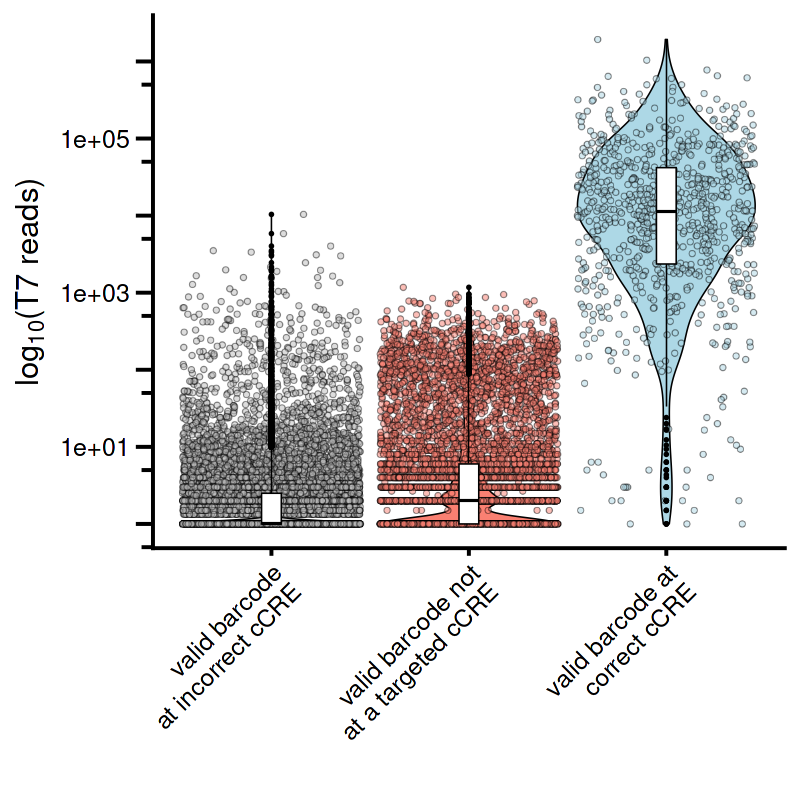

In [20]:
all_reps <- rbind(r1_t7_corrected,
                  r2_t7_corrected,
                  r3_t7_corrected)

all_reps <- aggregate(cbind(n_reads, n_umis) ~ location + barcode + overlapping_CRE +
                             CRE_barcode + valid_pairing + valid_barcode, 
                              data = all_reps, 
                              FUN = mean)

all_reps$type <- ifelse(all_reps$valid_pairing == "valid pairing" & all_reps$overlapping_CRE != "", "valid barcode at\ncorrect cCRE",

                ifelse(all_reps$overlapping_CRE != "" & 
                       all_reps$valid_barcode == "valid barcode" &
                       all_reps$valid_pairing != "valid pairing","valid barcode\nat incorrect cCRE", 

                ifelse(all_reps$overlapping_CRE != "" & 
                       all_reps$valid_barcode == "invalid barcode" ,"invalid barcode at\na targeted cCRE",  

                ifelse(all_reps$overlapping_CRE == "" & all_reps$valid_barcode == "valid barcode",
                       "valid barcode not\nat a targeted cCRE","other"))))

all_reps$type <- factor(all_reps$type, levels = c(
  "valid barcode\nat incorrect cCRE",
  "valid barcode not\nat a targeted cCRE",
  "valid barcode at\ncorrect cCRE"
))

options(repr.plot.width=4, repr.plot.height=4, repr.plot.res=200)
b <- ggplot(all_reps,aes(x=type,y=(n_reads),fill=type)) + 
      geom_violin(color="black",scale="width",linewidth=.2) +
      geom_jitter_rast(size=.8,width=.45,alpha=.5,shape=21,color="black",stroke=.2) +
      geom_boxplot(fill="white",color="black",width=.1,linewidth=.2,outlier.size = .01) +
      theme_classic() +
      theme(
        axis.line = element_line(color = "black"),
        panel.grid = element_blank(),legend.position="none",
        axis.text.x = element_text(angle = 45, hjust = 1)
        ) + labs(x="") + 
      scale_fill_manual(values=c("grey","salmon","lightblue")) +
      ylab(bquote(log[10]*.("(T7 reads)"))) + scale_y_log10(guide = "axis_logticks")
b

# ggsave(b,
#        file = '../figures/Fig3B.pdf', 
#        width = 70, 
#        height = 75,
#        units = 'mm')

### Figure 3C
Correlation scatter plots between technical replicates for each of the location barcode types shown in 3B:

In [21]:
compare_rep_mini <- function(rep1, rep2, r1, r2, c_, circle_points = NULL) {
    
  rep1$location_barcode <- paste0(rep1$location,"_",rep1$barcode)  
  rep2$location_barcode <- paste0(rep2$location,"_",rep2$barcode)  
    
  # Filter rep1 and rep2 for valid pairing, selecting CRE_barcode, n_umis, and overlapping_CRE.
  rep1 <- rep1[, c("location_barcode", "n_reads", "overlapping_CRE")]
  rep1$type <- "rep1"
  colnames(rep1) <- c("CRE_barcode", "n_umis", "overlapping_CRE")
    
  rep2 <- rep2[, c("location_barcode", "n_reads", "overlapping_CRE")]
  rep2$type <- "rep2"
  colnames(rep2) <- c("CRE_barcode", "n_umis", "overlapping_CRE")
  # Perform a full outer join on CRE_barcode
  merged_df <- merge(rep1, rep2, by = "CRE_barcode", all = TRUE, 
                      suffixes = c(".rep1", ".rep2"))
  
  # Replace NA values with zero in the n_umis columns
  merged_df$n_umis.rep1[is.na(merged_df$n_umis.rep1)] <- 0
  merged_df$n_umis.rep2[is.na(merged_df$n_umis.rep2)] <- 0
  
  # Rename columns for clarity:
  colnames(merged_df)[colnames(merged_df) == "n_umis.rep1"] <- "n_umis"
  colnames(merged_df)[colnames(merged_df) == "n_umis.rep2"] <- "rep2_umis"
  
  rep1 <- merged_df  # rep1 now holds the merged data
    
  if (!is.null(circle_points)) {
    rep1$circle_point <- rep1$CRE_barcode %in% circle_points
  } else { rep1$circle_point <- FALSE }
  
  # For correlation calculations, subset to rows with at least 50 UMIs in both replicates
  subset_corr <- rep1[rep1$n_umis >= 1 & rep1$rep2_umis >= 1, ]
  pearson_corr <- cor(log10(subset_corr$n_umis), log10(subset_corr$rep2_umis), method = "pearson")
  spearman_corr <- cor(log10(subset_corr$n_umis), log10(subset_corr$rep2_umis), method = "spearman")
  
  
  # Build the plot using ggplot2
  p <- ggplot(rep1, aes(x = log10(n_umis), y = log10(rep2_umis))) +
#     geom_smooth(data = subset_corr,
#                 aes(x = log10(n_umis), y = log10(rep2_umis)),
#                 method = "lm", color = "blue", inherit.aes = FALSE) +
    geom_point_rast(shape = 21, size = 1, alpha = 0.5,fill=c_,stroke=.1) +
    theme_classic() +
    theme(plot.title = element_text(size = 11),
          axis.line = element_line(color = "black"),
          panel.grid = element_blank(),
          legend.position = "none",
          axis.text.x = element_text()) +
      labs(
        title = "",
        y = bquote(log[10]*.(paste0("(",r1," reads)"))),
        x = bquote(log[10]*.(paste0("(",r2," reads)")))) +
#     geom_hline(yintercept = log10(1), linetype = "dashed", color = "salmon", size = 1) +
#     geom_vline(xintercept = log10(1), linetype = "dashed", color = "salmon", size = 1) + 
#     ggtitle(paste("Pearson:", signif(pearson_corr, 2),"\nSpearman:", signif(spearman_corr, 2)))
    ggtitle(paste0("r = ", signif(pearson_corr, 2),
               "\nρ = ", signif(spearman_corr, 2))) +
    geom_point_rast(data = rep1[rep1$circle_point, ],
                shape = 21,
                size = 2.5,
                alpha = 1,
                fill = NA,
                color = "#3636d1",
                stroke = 0.4)
  
  return(p)
}

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'ρ = 0.69' in 'mbcsToSbcs': dot substituted for <cf>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'ρ = 0.69' in 'mbcsToSbcs': dot substituted for <81>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'ρ = -0.42' in 'mbcsToSbcs': dot substituted for <cf>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'ρ = -0.42' in 'mbcsToSbcs': dot substituted for <81>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'ρ = 0.97' in 'mbcsToSbcs': dot substituted for <cf>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'ρ = 0.97' in 'mbcsToSbcs': dot substituted for <81>”
Warning message in grid.Call.graphics(C_text

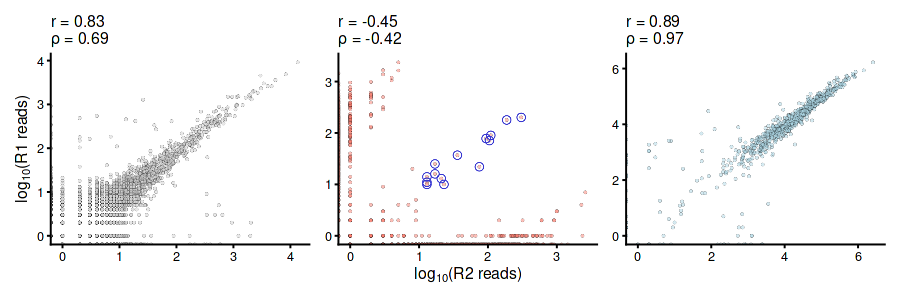

In [22]:
options(repr.plot.width=3, repr.plot.height=3, repr.plot.res=100)
a <- compare_rep_mini(r1_t7_corrected[r1_t7_corrected$valid_pairing == "valid pairing",],
                 r2_t7_corrected[r2_t7_corrected$valid_pairing == "valid pairing",],
                 "R1","R2","lightblue") 




##################################
#
##################################
r1.tmp <- r1_t7_corrected[r1_t7_corrected$valid_barcode == "valid barcode" & 
                          r1_t7_corrected$overlapping_CRE == "",]

r2.tmp <- r2_t7_corrected[r2_t7_corrected$valid_barcode == "valid barcode" & 
                          r2_t7_corrected$overlapping_CRE == "",]

r1.tmp$location_barcode <- paste0(r1.tmp$location, "_", r1.tmp$barcode)
r2.tmp$location_barcode <- paste0(r2.tmp$location, "_", r2.tmp$barcode)

merged <- merge(
    r1.tmp[, c("location_barcode", "n_reads")],
    r2.tmp[, c("location_barcode", "n_reads")],
    by = "location_barcode",
    all = TRUE,
    suffixes = c(".r1", ".r2")
)

merged$n_reads.r1[is.na(merged$n_reads.r1)] <- 0
merged$n_reads.r2[is.na(merged$n_reads.r2)] <- 0

circle_points <- merged[
    merged$n_reads.r1 >= 10 & merged$n_reads.r2 >= 10,
]$location_barcode

options(repr.plot.width=3, repr.plot.height=3, repr.plot.res=100)
b <- compare_rep_mini(r1_t7_corrected[r1_t7_corrected$valid_barcode == "valid barcode" & 
                                 r1_t7_corrected$overlapping_CRE == "",],
                 r2_t7_corrected[r2_t7_corrected$valid_barcode == "valid barcode" & 
                                 r2_t7_corrected$overlapping_CRE == "",],
                 "R1","R2","salmon",circle_points)


options(repr.plot.width=3, repr.plot.height=3, repr.plot.res=100)
c <- compare_rep_mini(r1_t7_corrected[r1_t7_corrected$valid_barcode == "valid barcode" & 
                                 r1_t7_corrected$overlapping_CRE != "" &
                                 r1_t7_corrected$valid_pairing != "valid pairing",],
                 r2_t7_corrected[r2_t7_corrected$valid_barcode == "valid barcode" & 
                                 r2_t7_corrected$overlapping_CRE != "" &
                                 r2_t7_corrected$valid_pairing != "valid pairing",],
                 "R1","R2","lightgrey")

options(repr.plot.width=9, repr.plot.height=3, repr.plot.res=100)

layout <- "
ABC
"

fig3C <- (c + b + a) +
  plot_layout(nrow = 1, guides = "collect", axes = "collect")
fig3C

ggsave('../figures/Fig3C.pdf', plot = fig3C, width = 75, height = 46, useDingbats = F, units = 'mm', device = 'pdf')

### Relevant metrics mentioned in main text:

In [23]:
# TNC barcode sequences
tnc_barcodes <- oligos[
  grepl("EH38", oligos$del_id) == FALSE &
    grepl("NTC", oligos$del_id) == FALSE,
]$barcode

valid_ccre <- all_reps$type == "valid barcode at\ncorrect cCRE" &
  !(all_reps$barcode %in% tnc_barcodes)

off_target_valid <- all_reps$type == "valid barcode not\nat a targeted cCRE"

incorrect_ccre <- all_reps$type == "valid barcode\nat incorrect cCRE"

n_CRE_captured <- length(unique(all_reps[valid_ccre, ]$CRE_barcode))
pct_CRE_captured <- 100 * n_CRE_captured / 800

cat(sprintf(
  "# of cCRE-targeting barcodes captured: %d / 800 (%.1f%%)\n\n",
  n_CRE_captured,
  pct_CRE_captured
))

cat(sprintf(
  "Valid barcode at correct cCRE: mean = %.1f reads, SD = %.1f\n",
  mean(all_reps[valid_ccre, ]$n_reads),
  sd(all_reps[valid_ccre, ]$n_reads)
))

cat(sprintf(
  "Valid barcode not at targeted cCRE: mean = %.1f reads, SD = %.1f\n",
  mean(all_reps[off_target_valid, ]$n_reads),
  sd(all_reps[off_target_valid, ]$n_reads)
))

cat(sprintf(
  "Valid barcode at incorrect cCRE: mean = %.1f reads, SD = %.1f\n",
  mean(all_reps[incorrect_ccre, ]$n_reads),
  sd(all_reps[incorrect_ccre, ]$n_reads)
))

# of cCRE-targeting barcodes captured: 792 / 800 (99.0%)

Valid barcode at correct cCRE: mean = 46677.3 reads, SD = 114505.1
Valid barcode not at targeted cCRE: mean = 24.7 reads, SD = 72.8
Valid barcode at incorrect cCRE: mean = 10.4 reads, SD = 131.3


In [24]:
## Add replicate labels before combining
r1_t7_corrected$replicate <- "R1"
r2_t7_corrected$replicate <- "R2"
r3_t7_corrected$replicate <- "R3"

## Combine replicates
all_reps_raw <- rbind(
  r1_t7_corrected,
  r2_t7_corrected,
  r3_t7_corrected
)

## Replicate-level object: keeps replicate identity for replicate-count metrics
all_reps_by_rep <- aggregate(
  cbind(n_reads, n_umis) ~ replicate + location + barcode + overlapping_CRE +
    CRE_barcode + valid_pairing + valid_barcode,
  data = all_reps_raw,
  FUN = mean
)

## Assign event type
all_reps_by_rep$type <- ifelse(
  all_reps_by_rep$valid_pairing == "valid pairing" &
    all_reps_by_rep$overlapping_CRE != "",
  "valid barcode at\ncorrect cCRE",
  ifelse(
    all_reps_by_rep$overlapping_CRE != "" &
      all_reps_by_rep$valid_barcode == "valid barcode" &
      all_reps_by_rep$valid_pairing != "valid pairing",
    "valid barcode\nat incorrect cCRE",
    ifelse(
      all_reps_by_rep$overlapping_CRE != "" &
        all_reps_by_rep$valid_barcode == "invalid barcode",
      "invalid barcode at\na targeted cCRE",
      ifelse(
        all_reps_by_rep$overlapping_CRE == "" &
          all_reps_by_rep$valid_barcode == "valid barcode",
        "valid barcode not\nat a targeted cCRE",
        "other"
      )
    )
  )
)

all_reps_by_rep$type <- factor(
  all_reps_by_rep$type,
  levels = c(
    "valid barcode\nat incorrect cCRE",
    "valid barcode not\nat a targeted cCRE",
    "valid barcode at\ncorrect cCRE"
  )
)

## Event-level object: matches your previous summaries
## This collapses across replicates after type has been assigned
all_reps <- aggregate(
  cbind(n_reads, n_umis) ~ location + barcode + overlapping_CRE +
    CRE_barcode + valid_pairing + valid_barcode + type,
  data = all_reps_by_rep,
  FUN = mean
)

## Barcode sets
ntc_barcodes <- oligos[
  grepl("NTC", oligos$del_id),
]$barcode

tnc_barcodes <- oligos[
  !grepl("EH38", oligos$del_id) &
    !grepl("NTC", oligos$del_id),
]$barcode

## Event-level categories, matching previous metrics
valid_ccre <- all_reps$type == "valid barcode at\ncorrect cCRE" &
  !(all_reps$barcode %in% tnc_barcodes)

off_target_valid <- all_reps$type == "valid barcode not\nat a targeted cCRE"

incorrect_ccre <- all_reps$type == "valid barcode\nat incorrect cCRE"

ntc_location_barcodes <- all_reps$barcode %in% ntc_barcodes &
  all_reps$type == "valid barcode not\nat a targeted cCRE"

## Capture metric
n_CRE_captured <- length(unique(all_reps[valid_ccre, ]$CRE_barcode))
pct_CRE_captured <- 100 * n_CRE_captured / 800

cat(sprintf(
  "# of cCRE-targeting barcodes captured: %d / 800 (%.1f%%)\n\n",
  n_CRE_captured,
  pct_CRE_captured
))

## Same cCRE-targeting metric as before
cat(sprintf(
  "Valid barcode at correct cCRE: mean = %.1f reads, SD = %.1f\n",
  mean(all_reps[valid_ccre, ]$n_reads),
  sd(all_reps[valid_ccre, ]$n_reads)
))

cat(sprintf(
  "Valid barcode not at targeted cCRE: mean = %.1f reads, SD = %.1f\n",
  mean(all_reps[off_target_valid, ]$n_reads),
  sd(all_reps[off_target_valid, ]$n_reads)
))

cat(sprintf(
  "Valid barcode at incorrect cCRE: mean = %.1f reads, SD = %.1f\n\n",
  mean(all_reps[incorrect_ccre, ]$n_reads),
  sd(all_reps[incorrect_ccre, ]$n_reads)
))

## NTC-specific metrics, using event-level object for read counts
cat(sprintf(
  "NTC location barcodes: mean = %.1f reads, SD = %.1f\n",
  mean(all_reps[ntc_location_barcodes, ]$n_reads),
  sd(all_reps[ntc_location_barcodes, ]$n_reads)
))

cat(sprintf(
  "NTC location barcodes have %.1f-fold fewer reads than valid cCRE-targeting barcodes\n",
  mean(all_reps[valid_ccre, ]$n_reads) /
    mean(all_reps[ntc_location_barcodes, ]$n_reads)
))

## Replicate-count metric, using replicate-level object
ntc_location_barcodes_by_rep <- all_reps_by_rep$barcode %in% ntc_barcodes &
  all_reps_by_rep$type == "valid barcode not\nat a targeted cCRE"

ntc_df_by_rep <- all_reps_by_rep[ntc_location_barcodes_by_rep, ]

ntc_df_by_rep$location_id <- paste(
  ntc_df_by_rep$barcode,
  ntc_df_by_rep$location,
  sep = "_"
)

ntc_reps_per_location <- tapply(
  ntc_df_by_rep$replicate,
  ntc_df_by_rep$location_id,
  function(x) length(unique(x))
)

pct_single_rep <- 100 * mean(ntc_reps_per_location == 1)

cat(sprintf(
  "NTC location barcodes observed in only one replicate: %.1f%%\n",
  pct_single_rep
))

# of cCRE-targeting barcodes captured: 792 / 800 (99.0%)

Valid barcode at correct cCRE: mean = 46677.3 reads, SD = 114505.1
Valid barcode not at targeted cCRE: mean = 24.7 reads, SD = 72.8
Valid barcode at incorrect cCRE: mean = 10.4 reads, SD = 131.3

NTC location barcodes: mean = 29.0 reads, SD = 81.1
NTC location barcodes have 1608.6-fold fewer reads than valid cCRE-targeting barcodes
NTC location barcodes observed in only one replicate: 93.6%


In [25]:
all_reps <- rbind(r1_t7_corrected,
                  r2_t7_corrected,
                  r3_t7_corrected)

all_reps <- aggregate(cbind(n_reads, n_umis) ~ location + barcode + overlapping_CRE +
                             CRE_barcode + valid_pairing + valid_barcode, 
                              data = all_reps, 
                              FUN = sum)

all_reps$type <- ifelse(all_reps$valid_pairing == "valid pairing" & all_reps$overlapping_CRE != "", "valid barcode at\ncorrect cCRE",

                ifelse(all_reps$overlapping_CRE != "" & 
                       all_reps$valid_barcode == "valid barcode" &
                       all_reps$valid_pairing != "valid pairing","valid barcode\nat incorrect cCRE", 

                ifelse(all_reps$overlapping_CRE != "" & 
                       all_reps$valid_barcode == "invalid barcode" ,"invalid barcode at\na targeted cCRE",  

                ifelse(all_reps$overlapping_CRE == "" & all_reps$valid_barcode == "valid barcode",
                       "valid barcode not\nat a targeted cCRE","other"))))

all_reps$type <- factor(all_reps$type, levels = c(
  "valid barcode\nat incorrect cCRE",
  "valid barcode not\nat a targeted cCRE",
  "valid barcode at\ncorrect cCRE"
))




whitelist_barcodes <- unique(oligos$barcode)

# total reads for valid barcode at correct cCRE
n_on_target <- 100*sum(all_reps[all_reps$barcode %in% whitelist_barcodes &
         all_reps$type == "valid barcode at\ncorrect cCRE",]$n_reads) / 
sum(all_reps[all_reps$barcode %in% whitelist_barcodes,]$n_reads)

# total reads for valid barcode at an incorrect cCRE (but a cCRE)
n_mismatch <- 100*sum(all_reps[all_reps$barcode %in% whitelist_barcodes &
                               all_reps$type == "valid barcode\nat incorrect cCRE",]$n_reads) / 
sum(all_reps[all_reps$barcode %in% whitelist_barcodes,]$n_reads)

# total reads for valid barcode not at a cCRE
n_offtarget <- 100*sum(all_reps[all_reps$barcode %in% whitelist_barcodes &
                                all_reps$type == "valid barcode not\nat a targeted cCRE",]$n_reads) / 
sum(all_reps[all_reps$barcode %in% whitelist_barcodes,]$n_reads)

cat(sprintf(
  "Percent of reads with valid barcodes:\n
  - Correct barcode-cCRE pairing: %s%%\n
  - Incorrect barcode-cCRE pairing: %s%%\n
  - Valid barcode at non-targeted location: %s%%\n
  - Total accounted for: %s%%\n",
  signif(n_on_target, 3),
  signif(n_mismatch, 3),
  signif(n_offtarget, 3),
  signif(sum(n_on_target, n_mismatch, n_offtarget), 3)
))

Percent of reads with valid barcodes:

  - Correct barcode-cCRE pairing: 99.4%

  - Incorrect barcode-cCRE pairing: 0.379%

  - Valid barcode at non-targeted location: 0.269%

  - Total accounted for: 100%


In [26]:
# Off-target events only
offtarget <- all_reps_by_rep[
  all_reps_by_rep$type == "valid barcode not\nat a targeted cCRE",
]

# Unique event ID = barcode + genomic location
offtarget$event_id <- paste(
  offtarget$barcode,
  offtarget$location,
  sep = "_"
)

# Keep only events with >10 UMIs
offtarget_10 <- offtarget[offtarget$n_reads >= 10, ]

# Count replicates per event
rep_counts <- tapply(
  offtarget_10$replicate,
  offtarget_10$event_id,
  function(x) length(unique(x))
)

# Events seen in >=2 replicates
shared_events <- names(rep_counts[rep_counts >= 2])

shared_df <- offtarget_10[
  offtarget_10$event_id %in% shared_events,
]

# Compute fold-difference between replicate abundances
event_stats <- by(
  shared_df,
  shared_df$event_id,
  function(df) {

    vals <- df$n_umis

    data.frame(
      min_umis = min(vals),
      max_umis = max(vals),
      fold_diff = max(vals) / min(vals)
    )
  }
)

event_stats <- do.call(rbind, event_stats)

# Within 2-fold
recurrent_events <- rownames(
  event_stats[event_stats$fold_diff <= 2, ]
)

length(recurrent_events)

[1] 12

In [27]:
# Recurrent off-target locations only
recurrent_locs <- unique(sub(".*_", "", recurrent_events))

recurrent_df <- data.frame(
  recurrent_location = recurrent_locs,
  chr = sub("-.*", "", recurrent_locs),
  pos = as.numeric(sub(".*-", "", recurrent_locs)),
  stringsAsFactors = FALSE
)

# Valid pairing locations
valid_df <- all_reps[
  all_reps$valid_pairing == "valid pairing",
]

valid_locs <- unique(valid_df$location)

valid_loc_df <- data.frame(
  valid_location = valid_locs,
  chr = sub("-.*", "", valid_locs),
  pos = as.numeric(sub(".*-", "", valid_locs)),
  stringsAsFactors = FALSE
)

# Find valid-pairing locations within 20 bp of each recurrent off-target location
nearby <- do.call(
  rbind,
  lapply(seq_len(nrow(recurrent_df)), function(i) {

    sub_valid <- valid_loc_df[
      valid_loc_df$chr == recurrent_df$chr[i],
    ]

    sub_valid$recurrent_location <- recurrent_df$recurrent_location[i]
    sub_valid$recurrent_pos <- recurrent_df$pos[i]
    sub_valid$distance_bp <- abs(sub_valid$pos - recurrent_df$pos[i])

    sub_valid <- sub_valid[
      sub_valid$distance_bp <= 100,
    ]

    sub_valid
  })
)

nearby <- nearby[
  order(nearby$recurrent_location, nearby$distance_bp),
]

nearby

,valid_location,chr,pos,recurrent_location,recurrent_pos,distance_bp
,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>
51,chr16-22298597,chr16,22298597,chr16-22298598,22298598,1
50,chr16-22298522,chr16,22298522,chr16-22298598,22298598,76
79,chr19-19407194,chr19,19407194,chr19-19407195,19407195,1
80,chr19-19407160,chr19,19407160,chr19-19407195,19407195,35
791,chr19-19407194,chr19,19407194,chr19-19407196,19407196,2
801,chr19-19407160,chr19,19407160,chr19-19407196,19407196,36
194,chr8-30912008,chr8,30912008,chr8-30912009,30912009,1
195,chr8-30911984,chr8,30911984,chr8-30912009,30912009,25


### Figure 3E
First, getting a list of file prefixes and CRE ids for the 8 CREs we performed targeted amplicon sequencing for:

In [28]:
prefixes <- readLines("../../CRE-deletion-validations_K562-3N-3d-top100/prefixes.fofn")
CREs <- unique(sub("_.*", "", prefixes))

Next, for each replicate, reading in the 8 CRE files for that replicate and combining into a single dataframe:

In [29]:
edit_R1 <- as.data.frame(matrix(ncol=0,nrow=0))
edit_R2 <- as.data.frame(matrix(ncol=0,nrow=0))
edit_R3 <- as.data.frame(matrix(ncol=0,nrow=0))

for (prefix in prefixes) {
    
    file <- paste0("../../CRE-deletion-validations_K562-3N-3d-top100/counts/",prefix,".MAPQ20.tsv")
    CRE <- sub("_.*", "", prefix)
    replicate <- sub("^[^_]+_([^_]+)_.*$", "\\1", prefix)
    
    count_df <- read.delim(file, header = TRUE, stringsAsFactors = FALSE)
    
    count_df <- count_df[grepl(CRE, count_df$Reference) == TRUE, ]
    
    
    count_df$umi_percent <- count_df$UMI_Count / sum(count_df$UMI_Count)
    count_df$read_percent <- count_df$Read_Count / sum(count_df$Read_Count)
    count_df$sample <- prefix
    count_df$type <- ifelse(count_df$Reference %in% CREs,"WT","deletion")
    
    count_df$replicate <- replicate
    
    if (replicate == "R1") {
        edit_R1 <- rbind(edit_R1,count_df)
    } else if (replicate == "R2") {
        edit_R2 <- rbind(edit_R2,count_df)
    } else if (replicate == "R3") {
        edit_R3 <- rbind(edit_R3,count_df)
    }
}

columns <- c("del_id","n_reads","n_umis",
                       "umi_efficiency","read_efficiency",
                       "sample","type","replicate")

colnames(edit_R1) <- columns
colnames(edit_R2) <- columns
colnames(edit_R3) <- columns

100*sum(edit_R1[grepl("_",edit_R1$del_id) == TRUE,]$umi_efficiency)
100*sum(edit_R2[grepl("_",edit_R2$del_id) == TRUE,]$umi_efficiency)
100*sum(edit_R3[grepl("_",edit_R3$del_id) == TRUE,]$umi_efficiency)

[1] 4.079572

[1] 5.000058

[1] 4.535552

In [30]:
oligos$CRE_id <- sub("_.*", "", oligos$del_id)

add_edits <- function(t7_df,edit_df) {
    
    # Only look at valid cCRE-barcode pairings
    t7_df <- t7_df[t7_df$valid_pairing == "valid pairing",]

    # If there are any barcodes that had multiple locations
    # at the same cCRE, aggregate their counts (likely alignment
    # jitter)
    t7_df <- aggregate(cbind(n_reads, n_umis) ~ .,
                       data = t7_df[, !(colnames(t7_df) %in% c("location"))],
                       FUN = sum)
    
    # Using the barcode sequence, add the enhancer annotation name and 
    # the deletion ID that was given to each designed oligo
    t7_df$CRE <- oligos$CRE_id[match(t7_df$barcode,oligos$barcode)]
    t7_df$del_id <- oligos$del_id[match(t7_df$barcode,oligos$barcode)]
    
    # Using the deletion ID, adding the amplicon sequencing edited UMIs
    # and amplicon sequencing edit efficiency (from UMI count)
    t7_df$edit_umis <- edit_df$n_umis[match(t7_df$del_id,edit_df$del_id)]
    t7_df$edit_efficiency <- edit_df$umi_efficiency[match(t7_df$del_id,edit_df$del_id)]
    # Setting NAs to zero
    t7_df$edit_umis[is.na(t7_df$edit_umis)] <- 0
    t7_df$edit_efficiency[is.na(t7_df$edit_efficiency)] <- 0
    
    # Adding pegRNA abundance information
    t7_df$pegRNA_umis <- pegRNA_counts$n_umis[match(t7_df$del_id,pegRNA_counts$del_id)]
    
    t7_df$pegRNA_ratio <- pegRNA_counts$ratio[match(t7_df$del_id, pegRNA_counts$del_id)]
    
    t7_df$t7_score <- (t7_df$n_umis / sum(t7_df$n_umis, na.rm = TRUE)) / t7_df$pegRNA_ratio
    t7_df$edit_score <- t7_df$edit_efficiency / t7_df$pegRNA_ratio
    t7_df
}

r1_edits <- add_edits(r1_t7_corrected, edit_R1)
r2_edits <- add_edits(r2_t7_corrected, edit_R2)
r3_edits <- add_edits(r3_t7_corrected, edit_R3)

In [31]:
# Step 1: row‐bind the three data frames
all_edits <- rbind(
  r1_edits[, c("del_id","CRE","barcode","overlapping_CRE","n_umis","n_reads",
            "pegRNA_ratio","t7_score","edit_umis","edit_efficiency")],
  r2_edits[, c("del_id","CRE","barcode","overlapping_CRE","n_umis","n_reads",
            "pegRNA_ratio","t7_score","edit_umis","edit_efficiency")],
  r3_edits[, c("del_id","CRE","barcode","overlapping_CRE","n_umis","n_reads",
            "pegRNA_ratio","t7_score","edit_umis","edit_efficiency")]
)

# Step 2: aggregate the numeric columns by the four character columns,
# taking the mean of each numeric column
all_edits <- aggregate(
  cbind(n_umis, n_reads, pegRNA_ratio, t7_score, edit_umis, edit_efficiency) 
    ~ del_id + CRE + barcode + overlapping_CRE,
  data = all_edits,
  FUN = mean,
  na.rm = TRUE
)

all_edits$edit_score <- all_edits$edit_efficiency / all_edits$pegRNA_ratio

`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_smooth()`).”
`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_smooth()`).”


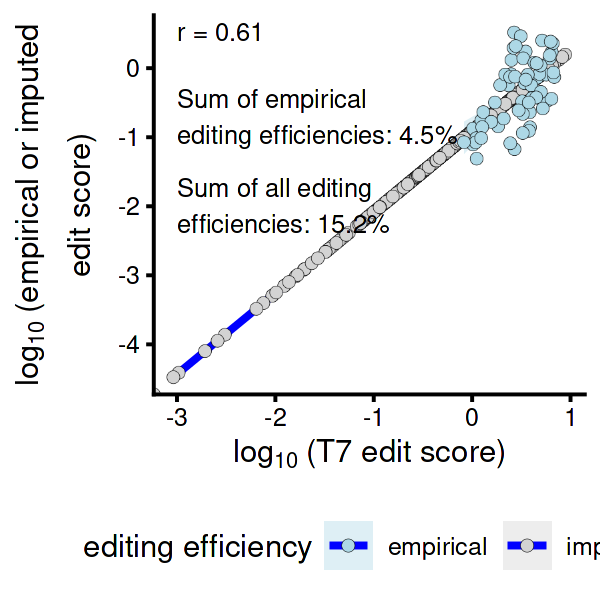

In [32]:
# 1. Subset the data

# Empirical data: rows with observed edit_efficiency
df_empirical <- all_edits[
  all_edits$CRE %in% CREs &
  all_edits$edit_umis > 10,
]

# Missing data: rows without empirical edit_efficiency
df_missing <- all_edits[
  !(all_edits$CRE %in% CREs),
]

# Filter empirical data for valid values
good <- is.finite(log10(df_empirical$t7_score)) &
        is.finite(log10(df_empirical$edit_score))

df_empirical <- df_empirical[good, ]

# 2. Fit a regression model on the empirical data using log-transformed values.
model <- lm(log10(edit_score) ~ log10(t7_score),
            data = df_empirical)

# 3. Predict the log10(edit_score) for the missing data rows.
df_missing$pred_log10_edit_score <- predict(model,
                                            newdata = df_missing)

# Convert the predictions back to the original scale:
df_missing$pred_edit_score <- 10^(df_missing$pred_log10_edit_score)

# For plotting, assign the predicted edit_score to a column
df_missing$edit_score <- df_missing$pred_edit_score

# 4. Combine the empirical and missing datasets
common_cols <- c("del_id", "t7_score", "edit_score")

df_empirical_sub <- df_empirical[, common_cols]
df_missing_sub   <- df_missing[, common_cols]

df_combined <- rbind(df_empirical_sub,
                     df_missing_sub)


# Add metadata back
df_combined$pegRNA_ratio <- all_edits$pegRNA_ratio[
  match(df_combined$del_id, all_edits$del_id)
]

df_combined$CRE <- all_edits$CRE[
  match(df_combined$del_id, all_edits$del_id)
]


# Exclude TNC barcdoes
df_combined <- df_combined[
    grepl("EH38D",df_combined$CRE) == TRUE,
  ]

# Recover raw editing efficiency
df_combined$edit_efficiency <- 
  df_combined$edit_score * df_combined$pegRNA_ratio

total_eff <- 100 * sum(df_combined$edit_efficiency)

df_combined$`editing efficiency` <- ifelse(
  df_combined$CRE %in% CREs,
  "empirical",
  "imputed"
)

# Correlation on empirical points only
emp <- df_combined[
  df_combined$`editing efficiency` == "empirical",
]

pearson_r <- cor(
  log10(emp$t7_score),
  log10(emp$edit_score),
  method = "pearson"
)

label_pear <- paste0(
  "r = ",
  signif(pearson_r, 2)
)





a <- ggplot(
  df_combined[
    rev(order(df_combined$`editing efficiency`)),
  ],
  aes(
    x = log10(t7_score),
    y = log10(edit_score),
    fill = `editing efficiency`,
    color = `editing efficiency`
  )
) +

  geom_smooth(method = "glm",
              color = "blue",
              se = TRUE) +

  geom_point_rast(shape = 21,
                  size = 2,
                  stroke = .1) +

  scale_fill_manual(values = c("lightblue",
                               "lightgrey")) +

  scale_color_manual(values = c("black",
                                "black")) +

  theme_classic() +

  theme(
    axis.line = element_line(color = "black"),
    panel.grid = element_blank(),
    legend.position = "bottom"
  ) +

  labs(
    x = expression(log[10]~"(T7 edit score)"),
    y = expression(
    atop(
      log[10]~"(empirical or imputed",
      "edit score)"
    )
  )
  ) +

  annotate(
    "text",
    x = -3,
    y = 0.4,
    label = label_pear,
    hjust = 0,
    vjust = 0,
    size = 9/.pt
  ) +

  annotate(
    "text",
    x = -3,
    y = .5,
    label = paste0(
      "Sum of empirical\nediting efficiencies: ",
      signif(
        100 * sum(df_empirical$edit_efficiency),
        2
      ),
      "%"
    ),
    hjust = 0,
    vjust = 2,
    size = 9/.pt
  ) +

  annotate(
    "text",
    x = -3,
    y = -.8,
    label = paste0(
      "Sum of all editing\nefficiencies: ",
      signif(total_eff, 3),
      "%"
    ),
    hjust = 0,
    vjust = 2,
    size = 9/.pt
  )

options(repr.plot.width=3,
        repr.plot.height=3,
        repr.plot.res=200)
a

ggsave('../figures/Fig3E.pdf', plot = a, width = 75, height = 70, useDingbats = F, units = 'mm', device = 'pdf')

In [33]:
length(df_combined[
    grepl("EH38D",df_combined$CRE) == TRUE,
  ]$del_id)

length(unique(all_reps[all_reps$type == "valid barcode at\ncorrect cCRE" & !(all_reps$barcode %in% tnc_barcodes),]$barcode))

[1] 791

[1] 792

In [34]:
nrow(df_combined[df_combined$`editing efficiency` != "empirical" & grepl("EH38D",df_combined$CRE) == TRUE,]) + 
nrow(df_combined[df_combined$`editing efficiency` == "empirical"& grepl("EH38D",df_combined$CRE) == TRUE,]) 

[1] 791

In [35]:
signif(total_eff, 3)

[1] 15.2

### Figure 3F

In [36]:
cols_ <- c("del_id", "CRE", "barcode", "overlapping_CRE",
           "n_umis", "n_reads",
           "pegRNA_ratio", "t7_score",
           "edit_umis", "edit_efficiency", "edit_score")

r1_rep <- r1_edits[, cols_]
r1_rep$rep <- "R1"

r2_rep <- r2_edits[, cols_]
r2_rep$rep <- "R2"

r3_rep <- r3_edits[, cols_]
r3_rep$rep <- "R3"

all_reps <- rbind(r1_rep, r2_rep, r3_rep)

out_df <- as.data.frame(matrix(ncol = 0, nrow = 0))

for (CRE in CREs) {

    sub_df <- all_reps[all_reps$CRE == CRE, ]

    sub_df$spacer1 <- toupper(oligos$spacer1[match(sub_df$del_id, oligos$del_id)])
    sub_df$spacer2 <- toupper(oligos$spacer2[match(sub_df$del_id, oligos$del_id)])

    agg <- aggregate(
        cbind(edit_score, t7_score) ~ spacer2 + rep,
        data  = sub_df,
        FUN   = mean,
        na.rm = TRUE
    )



    # Make sure rows are ordered by rep and spacer2
    agg <- agg[order(agg$rep, agg$spacer2), ]

    # 2) Identify the two spacer2 levels
    sp_vals <- unique(agg$spacer2)

    # 3) edit efficiency score
    A_by_rep <- agg$edit_score[
        agg$spacer2 == sp_vals[1]
    ]

    B_by_rep <- agg$edit_score[
        agg$spacer2 == sp_vals[2]
    ]

    eff_fc <- mean(A_by_rep) / mean(B_by_rep)

    eff_p <- t.test(
        A_by_rep,
        B_by_rep,
        paired = TRUE
    )$p.value

    # 4) T7 score
    A_by_rep <- agg$t7_score[
        agg$spacer2 == sp_vals[1]
    ]

    B_by_rep <- agg$t7_score[
        agg$spacer2 == sp_vals[2]
    ]

    t7_fc <- mean(A_by_rep) / mean(B_by_rep)

    t7_p <- t.test(
        A_by_rep,
        B_by_rep,
        paired = TRUE
    )$p.value

    spacers <- paste(sp_vals, collapse = "\n")

    out_df <- rbind(
        out_df,
        c(
            spacers,
            eff_fc,
            eff_p,
            t7_fc,
            t7_p
        )
    )
}

colnames(out_df) <- c(
    "spacers",
    "efficiency_FC",
    "efficiency_p.val",
    "t7_FC",
    "t7_p.val"
)

out_df$efficiency_FC <- as.numeric(
    out_df$efficiency_FC
)

out_df$efficiency_p.val <- as.numeric(
    out_df$efficiency_p.val
)

out_df$t7_FC <- as.numeric(
    out_df$t7_FC
)

out_df$t7_p.val <- as.numeric(
    out_df$t7_p.val
)

out_df$t7_p.val <- p.adjust(
    out_df$t7_p.val,
    method = "BH"
)

out_df$efficiency_p.val <- p.adjust(
    out_df$efficiency_p.val,
    method = "BH"
)

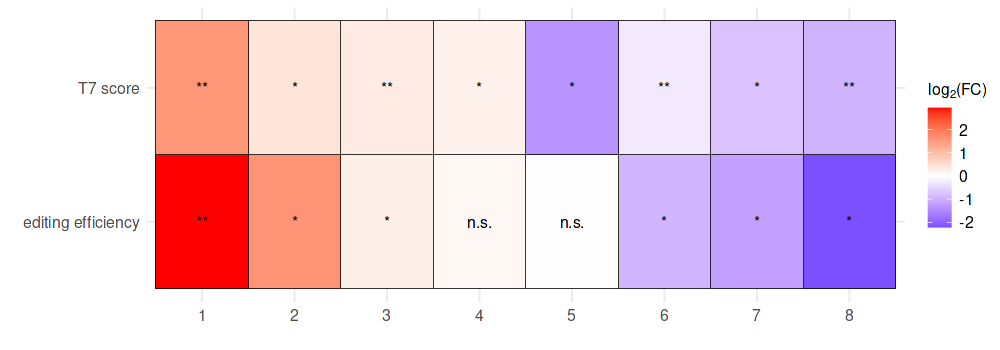

In [37]:
# 1) Pull out just the columns you care about
df <- out_df[, c("spacers", "efficiency_FC", "t7_FC")]

# 2) Determine the desired x-axis order
spacer_order <- df$spacers[order(df$efficiency_FC, decreasing = TRUE)]
spacer_order <- unique(spacer_order)

# 3) Melt for the heatmap
df_long <- melt(df, id.vars = "spacers")

# 4) Turn spacers into ordered factor
df_long$spacers <- factor(df_long$spacers, levels = spacer_order)

df_long$variable <- ifelse(
  df_long$variable == "t7_FC", "T7 score",
  ifelse(df_long$variable == "efficiency_FC", "editing efficiency", "")
)

df_long$id <- paste0(df_long$spacers, "_", df_long$variable)

df_p <- out_df[, c("spacers", "efficiency_p.val", "t7_p.val")]
df_p <- melt(df_p, id.vars = "spacers")

df_p$variable <- ifelse(
  df_p$variable == "t7_p.val", "T7 score",
  ifelse(df_p$variable == "efficiency_p.val", "editing efficiency", "")
)

df_p$id <- paste0(df_p$spacers, "_", df_p$variable)

df_long$p.value <- df_p$value[match(df_long$id, df_p$id)]

df_long$sig <- ifelse(
  df_long$p.value < 0.001, "***",
  ifelse(
    df_long$p.value < 0.01, "**",
    ifelse(df_long$p.value < 0.05, "*", "n.s.")
  )
)

# Map each spacer to numeric rank based on factor level
rank_map <- setNames(
  seq_along(levels(df_long$spacers)),
  levels(df_long$spacers)
)

df_long$y_lab <- as.character(
  rank_map[as.character(df_long$spacers)]
)

options(repr.plot.width = 10,
        repr.plot.height = 3.5,
        repr.plot.res = 100)

a <- ggplot(
  df_long,
  aes(x = y_lab, y = variable, fill = log2(value))
) +
  geom_tile(color = "black") +
  scale_fill_gradient2(
    low = "blue",
    mid = "white",
    high = "red",
    midpoint = 0
  ) +
  theme_minimal() +
  theme(
      text = element_text(size = 11),
      axis.text = element_text(size = 11),
      axis.title = element_text(size = 11),
      legend.text = element_text(size = 11),
      legend.title = element_text(size = 11)
     )+
  labs(
    y = "",
    x = "",
    fill = bquote(log[2]*"(FC)")
  ) +
  geom_text(
    aes(label = sig),
    color = "black",
    size = 11/.pt
  )

a


ggsave('../figures/Fig3F.pdf', plot = a, width = 145, height = 35, useDingbats = F, units = 'mm', device = 'pdf')

### Figure 3D

In [38]:
read_variants <- function(rep) {
    
    file <- paste0("../../CRE-deletion-validations_K562-3N-3d-top100/counts/all_variant_counts_",rep,".MAPQ20.tsv")
    variant_df <- read.csv(file,sep="\t",header=TRUE)

    variant_df$rep <- toupper(rep)
    
    variant_df$variant <- ifelse(variant_df$variant == "del","deletion",
                          ifelse(variant_df$variant == "ins","insertion",      
                          ifelse(variant_df$variant == "sub","substitution",
                          ifelse(variant_df$variant == "reads","reads", ""))))
    variant_df
    
}

r1_variants <- read_variants("r1")
r2_variants <- read_variants("r2")
r3_variants <- read_variants("r3")

all_variants <- rbind(r1_variants,r2_variants,r3_variants)

plot_variant_profile <- function(all_variants, ref_name, start, end) {
    
  # Get location of insertion within reference
  cre_fa    <- readDNAStringSet("../../CRE-deletion-validations_K562-3N-3d-top100/250410_alignments/CRE-deletions.fa")
  seq       <- cre_fa[[ref_name]]
  motif1    <- DNAString("GTGCCAGTAGCACAGCAATT")
  motif2    <- DNAString("TAGTTGTGCTTTCCGCG")
  hits1     <- matchPattern(motif1, seq)
  hits2     <- matchPattern(motif2, seq)
  start_pos <- start(hits1)[1] -1
  end_pos   <- start(hits2)[1] + width(hits2)[1] + 8
    
  # Format title
  ref_label <- sub("_2$", "", ref_name)
  bc <- ifelse(grepl("_2$", ref_name), "2", "1")
    
  if (ref_label %in% oligos$del_id) {
      del <- oligos[oligos$del_id == ref_label,,drop=FALSE]$deletion_size
      cre <- sub("_.*$", "", ref_label)
      final_label <- paste0(cre," D",del," barcode #",bc)
  } else {
      final_label <- paste0(ref_name," WT")
  }
    
  # 1) subset to this reference
  df <- subset(all_variants, ref == ref_name)
  
  # 2) detect which X* columns actually have data
  pos_cols_all <- grep("^X\\d+", names(df), value = TRUE)
  pos_cols     <- pos_cols_all[sapply(pos_cols_all, function(col) {
    any(!is.na(df[[col]]))
  })]
  
  # 3) melt only those columns
  df_melt <- melt(
    df,
    id.vars       = c("ref","variant","rep","sample"),
    measure.vars  = pos_cols,
    variable.name = "position",
    value.name    = "freq"
  )
    
  reads_rows <- df_melt$variant == "reads"
  raw_reads   <- df_melt$freq[reads_rows]       # these are your raw counts
  avg_reads   <- mean(raw_reads, na.rm = TRUE)  # should be a real number, not NA


  
  # 4) clean up types
  df_melt$position <- as.integer(sub("^X","", df_melt$position))
  df_melt$freq     <- as.numeric(df_melt$freq)
  
  # 4b) convert raw counts → freqs by dividing each class by the reads row
  df_melt$reads_count <- ave(
    df_melt$freq * (df_melt$variant == "reads"),
    df_melt$rep,
    df_melt$position,
    FUN = function(x) max(x, na.rm = TRUE)
  )
  df_melt$freq <- df_melt$freq / df_melt$reads_count
  df_melt$reads_count <- NULL
  
    
    
    
  # 5) plot with na.rm = TRUE and y-limits 0–1
  ggplot(
    df_melt[df_melt$position > start &
            df_melt$position < end &
            df_melt$variant != "reads",],
    aes(x = position, y = freq, group = variant)
  ) +
    annotate("rect",
             xmin  = start_pos,
             xmax  = start_pos + 45,
             ymin  = 0,
             ymax  = 1,
             fill  = "red",
             alpha = 0.2
    ) +
    
    annotate("rect",
             xmin  = start_pos + 24,
             xmax  = start_pos + 24 + 54,
             ymin  = 0,
             ymax  = 1,
             fill  = "lightblue",
             alpha = 0.2
    ) +
    
    geom_vline(xintercept=start_pos,linetype="dashed",color="red") + 
    geom_vline(xintercept=start_pos + 45,linetype="dashed",color="red") + 
    
    geom_vline(xintercept=start_pos + 24,linetype="dashed",color="blue") + 
    geom_vline(xintercept=start_pos + 24 + 54,linetype="dashed",color="blue") + 
    
    stat_summary(
      fun.min = min, fun.max = max,
      geom    = "linerange",
      color   = "black",
      size    = 0.5, alpha = .5,
      na.rm   = TRUE
    ) +
    stat_summary(
      aes(color = variant),
      fun     = mean,
      geom    = "line",
      size    = 1,
      na.rm   = TRUE
    ) +
    labs(
      title = final_label,
      x     = "position along reference",
      y     = "Variant Frequency",
      color = ""
    ) +
    scale_y_continuous(limits = c(0, 1), expand = c(0, 0)) +
    theme_classic() + 
    theme(
      text = element_text(size = 24),
      axis.line = element_line(color = "black"),
      panel.grid = element_blank(),
      legend.position = "right"
    ) +
    scale_color_manual(values = c("#fc585b","#f5af4e","#5eb4ff","lightgrey")) + 
    annotate(
    "text",
    x     = 200,
    y     = 0.85,
    label = paste0("avg # reads: ", round(avg_reads)),
    hjust = 0, size=7
  )
}

In [39]:
out_df <- as.data.frame(matrix(ncol=0,nrow=0))
for (ref in unique(all_variants$ref[grepl("_",all_variants$ref)==TRUE])) {
    # Subset to 
    sub_df <- all_variants[all_variants$ref == ref,]
    
    # Get the location of the insertion
    cre_fa    <- readDNAStringSet("../../CRE-deletion-validations_K562-3N-3d-top100/250410_alignments/CRE-deletions.fa")
    seq       <- cre_fa[[ref]]
    motif1    <- DNAString("GTGCCAGTAGCACAGCAATT")
    motif2    <- DNAString("TAGTTGTGCTTTCCGCG")
    hits1     <- matchPattern(motif1, seq)
    hits2     <- matchPattern(motif2, seq)
    start_pos <- start(hits1)[1] -1
    end_pos   <- start(hits2)[1] + width(hits2)[1] + 8
    
    cols <- c("variant","rep",paste0("X",(start_pos-100):(end_pos+100)))
 
    sub_df <- sub_df[,cols]
    
    colnames(sub_df) <- c("variant","rep",1:length((start_pos-100):(end_pos+100)))
    sub_df$ref <- ref
    
    melt_df <- suppressMessages(melt(sub_df))

    read_df <- unique(melt_df[melt_df$variant == "reads",c("rep","value")])

    variant_df <- melt_df[melt_df$variant != "reads",]

    variant_df$total_reads <- read_df$value[match(variant_df$rep,read_df$rep)]
    
    out_df <- rbind(out_df,variant_df)
    
}

out_df$freq <- out_df$value / out_df$total_reads

variant_sub <- aggregate(
  cbind(value,total_reads) 
    ~ variable + variant + rep,
  data = out_df,
  FUN = sum,
  na.rm = TRUE
)

variant_sub$freq <- variant_sub$value / variant_sub$total_reads
variant_sub$position <- as.integer(variant_sub$variable)

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”


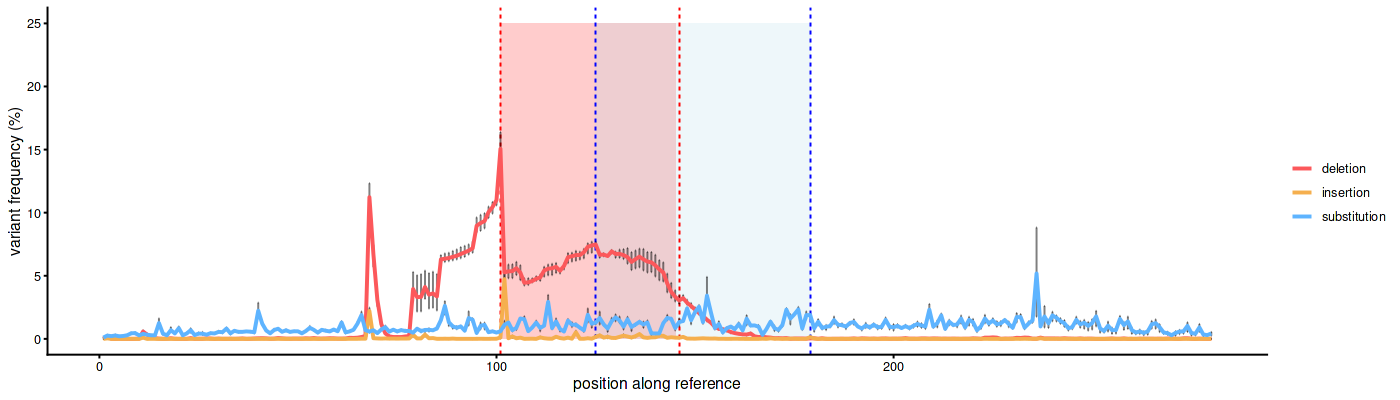

In [40]:
summary_df <- variant_sub %>%
  group_by(variant, position) %>%
  summarise(
    freq_mean = mean(freq, na.rm = TRUE),
    freq_min  = min(freq, na.rm = TRUE),
    freq_max  = max(freq, na.rm = TRUE),
    .groups   = "drop"
  )


options(repr.plot.width=14, repr.plot.height=4, repr.plot.res=100)
fig3D <- ggplot(summary_df, aes(x = position, y = 100*freq_mean, color = variant)) +

    annotate("rect",
             xmin  = 101,
             xmax  = 145,
             ymin  = 0,
             ymax  = 25,
             fill  = "red",
             alpha = 0.2
    ) +
    
    annotate("rect",
             xmin  = 101 + 24,
             xmax  = 101 + 24 + 54,
             ymin  = 0,
             ymax  = 25,
             fill  = "lightblue",
             alpha = 0.2
    ) +
    
    geom_vline(xintercept=101,linetype="dashed",color="red") + 
    geom_vline(xintercept=101 + 45,linetype="dashed",color="red") + 
    
    geom_vline(xintercept=101 + 24,linetype="dashed",color="blue") + 
    geom_vline(xintercept=101 + 24 + 54,linetype="dashed",color="blue") +


    geom_errorbar(
        aes(ymin = 100*freq_min, ymax = 100*freq_max),
        width = 0.2,
        alpha = 0.5,color="black"
    ) +
    geom_line(size = 1) +




    theme_classic() + 
    theme(
      
      axis.line = element_line(color = "black"),
      panel.grid = element_blank(),
      legend.position = "right"
    ) + 
    labs(color="",y="variant frequency (%)",x="position along reference") + 
    scale_color_manual(values = c("#fc585b","#f5af4e","#5eb4ff","lightgrey")) 

fig3D

### Supplementary Figure 8
Upstream processing done wiht *count_indel_types_full_window* function of *03_count_variants.ipynb* notebook:

In [41]:
read_partials <- function(rep,suff) {
    
    file <- paste0("../../CRE-deletion-validations_K562-3N-3d-top100/counts/indel_types_",rep,suff)
    partial_df <- read.csv(file,sep="\t",header=TRUE)
#     partial_df <- aggregate(cbind(no_deletion,with_deletion) ~ ref,
#                               data = partial_df,
#                               FUN = sum,
#                               na.rm = TRUE)
    
    
    partial_df$percent_perfect <- 100 * partial_df$perfect_reads / partial_df$total_reads
    partial_df$rep <- toupper(rep)
    partial_df
  
    
}

r1_partial <- read_partials("r1",".MAPQ20.fullwindow.tsv")
r2_partial <- read_partials("r2",".MAPQ20.fullwindow.tsv")
r3_partial <- read_partials("r3",".MAPQ20.fullwindow.tsv")

all_partial <- rbind(r1_partial,r2_partial,r3_partial)
all_partial$locus <- sub("_.*", "", all_partial$ref)

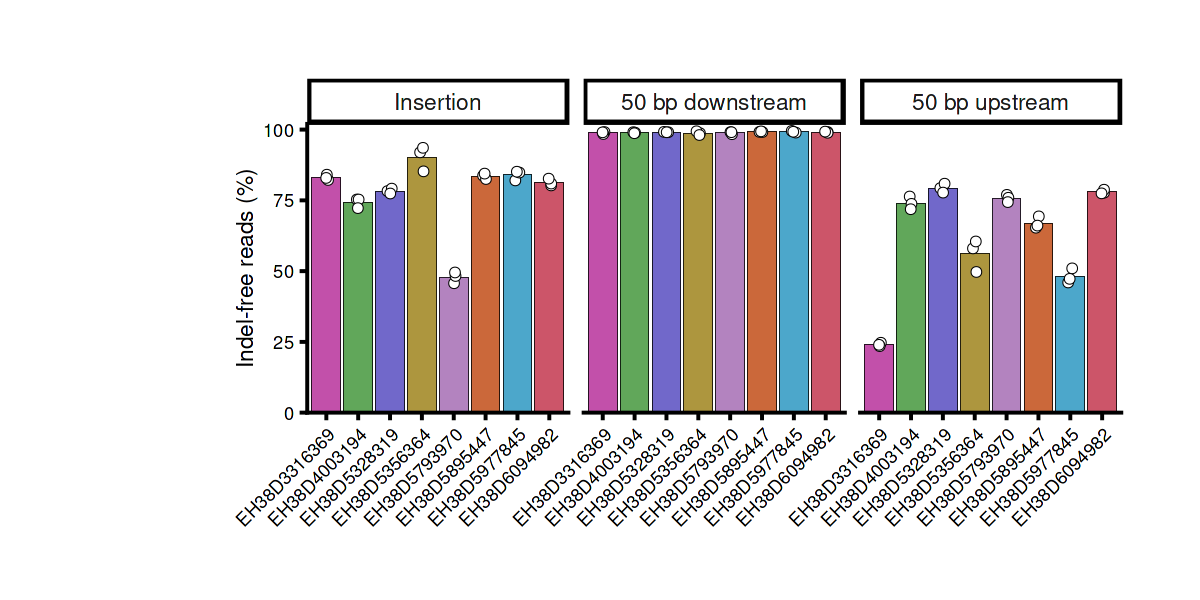

In [42]:
# Read-weighted percentage within each locus, region, and replicate
all_partial_locus_rep <- all_partial %>%
  group_by(locus, location, rep) %>%
  summarise(
    total_reads = sum(total_reads, na.rm = TRUE),
    indel_reads = sum(indel_reads, na.rm = TRUE),
    perfect_reads = sum(perfect_reads, na.rm = TRUE),
    percent_perfect = 100 * perfect_reads / total_reads,
    .groups = "drop"
  )

# Mean across the three replicate-level percentages
all_partial_locus_avg <- all_partial_locus_rep %>%
  group_by(locus, location) %>%
  summarise(
    percent_perfect = mean(percent_perfect, na.rm = TRUE),
    .groups = "drop"
  )

location_levels <- c("insertion", "downstream", "upstream")
location_labels <- c(
  "Insertion",
  "50 bp downstream",
  "50 bp upstream"
)

all_partial_locus_rep <- all_partial_locus_rep %>%
  mutate(
    location = factor(
      location,
      levels = location_levels,
      labels = location_labels
    )
  )

all_partial_locus_avg <- all_partial_locus_avg %>%
  mutate(
    location = factor(
      location,
      levels = location_levels,
      labels = location_labels
    )
  )

c_ <- c(
  "#c250aa",
  "#61a75a",
  "#7168ca",
  "#ad963e",
  "#b383bf",
  "#cb683a",
  "#4ca7cb",
  "#cc5569"
)

final <- ggplot(
  all_partial_locus_avg,
  aes(
    x = locus,
    y = percent_perfect,
    fill = locus
  )
) +
  geom_col(
    color = "black",
    width = 0.9,linewidth=.1
  ) +
  geom_point(
    data = all_partial_locus_rep,
    aes(
      x = locus,
      y = percent_perfect
    ),
    inherit.aes = FALSE,
    shape = 21,
    size = 1.5,
    stroke = 0.2,
    color = "black",
    fill = "white",
    position = position_jitter(
      width = 0.08,
      height = 0
    )
  ) +
  facet_wrap(~location, nrow = 1) +
  scale_fill_manual(values = c_, guide = "none") +
  scale_y_continuous(
    limits = c(0, 100),
    breaks = seq(0, 100, 25),
    expand = expansion(mult = c(0, 0.02))
  ) +
  labs(
    y = "Indel-free reads (%)",
    x = NULL
  ) +
  theme_classic() +
  theme(
    text = element_text(size = 8),
    axis.line = element_line(color = "black"),
    panel.grid = element_blank(),
    axis.text.x = element_text(angle = 45, hjust = 1),
    strip.text = element_text(size = 8),
    plot.margin = unit(c(1, 1, 1, 3), "cm")
  )
options(repr.plot.width=6, repr.plot.height=3, repr.plot.res=200)

final

### Supplementary Figure 10

In [43]:
compare_rep <- function(rep1, rep2, r1, r2) {
    
  # Filter rep1 and rep2 for valid pairing, selecting CRE_barcode, n_umis, and overlapping_CRE.
  rep1 <- rep1[rep1$type != "WT", c("del_id", "umi_efficiency")]
  rep1$type <- "rep1"
  rep2 <- rep2[rep2$type != "WT", c("del_id", "umi_efficiency")]
  rep2$type <- "rep2"
  
  # Perform a full outer join on CRE_barcode
  merged_df <- merge(rep1, rep2, by = "del_id", all = TRUE, 
                      suffixes = c(".rep1", ".rep2"))
  
  # Replace NA values with zero in the n_umis columns
  merged_df$umi_efficiency.rep1[is.na(merged_df$umi_efficiency.rep1)] <- 0
  merged_df$umi_efficiency.rep2[is.na(merged_df$umi_efficiency.rep2)] <- 0
  
  # Rename columns for clarity:
  colnames(merged_df)[colnames(merged_df) == "umi_efficiency.rep1"] <- "n_umis"
  colnames(merged_df)[colnames(merged_df) == "umi_efficiency.rep2"] <- "rep2_umis"
  
  rep1 <- merged_df  # rep1 now holds the merged data
  
  # For correlation calculations, subset to rows with at least 50 UMIs in both replicates
  subset_corr <- rep1[
                      is.finite(log10(rep1$n_umis)) &
                      is.finite(log10(rep1$rep2_umis)), ]
    
    
  pearson_corr <- cor(log10(subset_corr$n_umis), log10(subset_corr$rep2_umis), method = "pearson")
  spearman_corr <- cor(log10(subset_corr$n_umis), log10(subset_corr$rep2_umis), method = "spearman")
  
  
  # Build the plot using ggplot2
  p <- ggplot(rep1, aes(x = log10(n_umis), y = log10(rep2_umis))) +
    geom_smooth(data = rep1,
                aes(x = log10(n_umis), y = log10(rep2_umis)),
                method = "lm", color = "blue", inherit.aes = FALSE) +
    geom_point_rast(shape = 21, size = 4, stroke=.1,alpha = 0.5,fill="lightblue") +
    annotate("text", x = -5, y = Inf, 
             label = paste("Pearson:", round(pearson_corr, 3)),
             hjust = 0, vjust = 2, size = 8/.pt) +
    annotate("text", x = -5, y = Inf, 
             label = paste("Spearman:", round(spearman_corr, 3)),
             hjust = 0, vjust = 4, size = 8/.pt) +
    theme_classic() +
    theme(
          axis.line = element_line(color = "black"),
          panel.grid = element_blank(),
          legend.position = "none",
          axis.text.x = element_text()) +
      labs(
        title = "",
        y = bquote(log[10]*.(paste0("(",r1," editing efficiency)"))),
        x = bquote(log[10]*.(paste0("(",r2," editing efficiency)")))) +
#     geom_hline(yintercept = log10(1), linetype = "dashed", color = "salmon", size = 1) +
#     geom_vline(xintercept = log10(1), linetype = "dashed", color = "salmon", size = 1) + 
    ggtitle(paste0(r1," vs ",r2))
  
  return(p)
}




compare_rep_t7 <- function(rep1, rep2, r1, r2) {
    
    
  # Filter rep1 and rep2 for valid pairing, selecting CRE_barcode, n_umis, and overlapping_CRE.
  rep1 <- rep1[rep1$CRE %in% CREs, c("del_id", "n_reads")]
  rep1$type <- "rep1"
  rep2 <- rep2[rep2$CRE %in% CREs, c("del_id", "n_reads")]
  rep2$type <- "rep2"
  
  # Perform a full outer join on CRE_barcode
  merged_df <- merge(rep1, rep2, by = "del_id", all = TRUE, 
                      suffixes = c(".rep1", ".rep2"))
  
  # Replace NA values with zero in the n_umis columns
  merged_df$n_reads.rep1[is.na(merged_df$n_reads.rep1)] <- 0
  merged_df$n_reads.rep2[is.na(merged_df$n_reads.rep2)] <- 0
  
  # Rename columns for clarity:
  colnames(merged_df)[colnames(merged_df) == "n_reads.rep1"] <- "n_umis"
  colnames(merged_df)[colnames(merged_df) == "n_reads.rep2"] <- "rep2_umis"
  
  rep1 <- merged_df  # rep1 now holds the merged data
  
  # For correlation calculations, subset to rows with at least 50 UMIs in both replicates
  subset_corr <- rep1[
                      is.finite(log10(rep1$n_umis)) &
                      is.finite(log10(rep1$rep2_umis)), ]
    
    
  pearson_corr <- cor(log10(subset_corr$n_umis), log10(subset_corr$rep2_umis), method = "pearson")
  spearman_corr <- cor(log10(subset_corr$n_umis), log10(subset_corr$rep2_umis), method = "spearman")
  
  
  # Build the plot using ggplot2
  p <- ggplot(rep1, aes(x = log10(n_umis), y = log10(rep2_umis))) +
    geom_smooth(data = rep1,
                aes(x = log10(n_umis), y = log10(rep2_umis)),
                method = "lm", color = "blue", inherit.aes = FALSE) +
    geom_point_rast(shape = 21, size = 4, stroke=.1,alpha = 0.5,fill="lightblue") +
    annotate("text", x = 3.5, y = Inf, 
             label = paste("Pearson:", round(pearson_corr, 3)),
             hjust = 0, vjust = 2, size = 8/.pt) +
    annotate("text", x = 3.5, y = Inf, 
             label = paste("Spearman:", round(spearman_corr, 3)),
             hjust = 0, vjust = 4, size = 8/.pt) +
    theme_classic() +
    theme(
          axis.line = element_line(color = "black"),
          panel.grid = element_blank(),
          legend.position = "none",
          axis.text.x = element_text()) +
      labs(
        title = "",
        y = bquote(log[10]*.(paste0("(",r1," T7 reads)"))),
        x = bquote(log[10]*.(paste0("(",r2," T7 reads)")))) +
#     geom_hline(yintercept = log10(1), linetype = "dashed", color = "salmon", size = 1) +
#     geom_vline(xintercept = log10(1), linetype = "dashed", color = "salmon", size = 1) + 
    ggtitle(paste0(r1," vs ",r2))
  
  return(p)
}


`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_smooth()`).”
`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_smooth()`).”
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


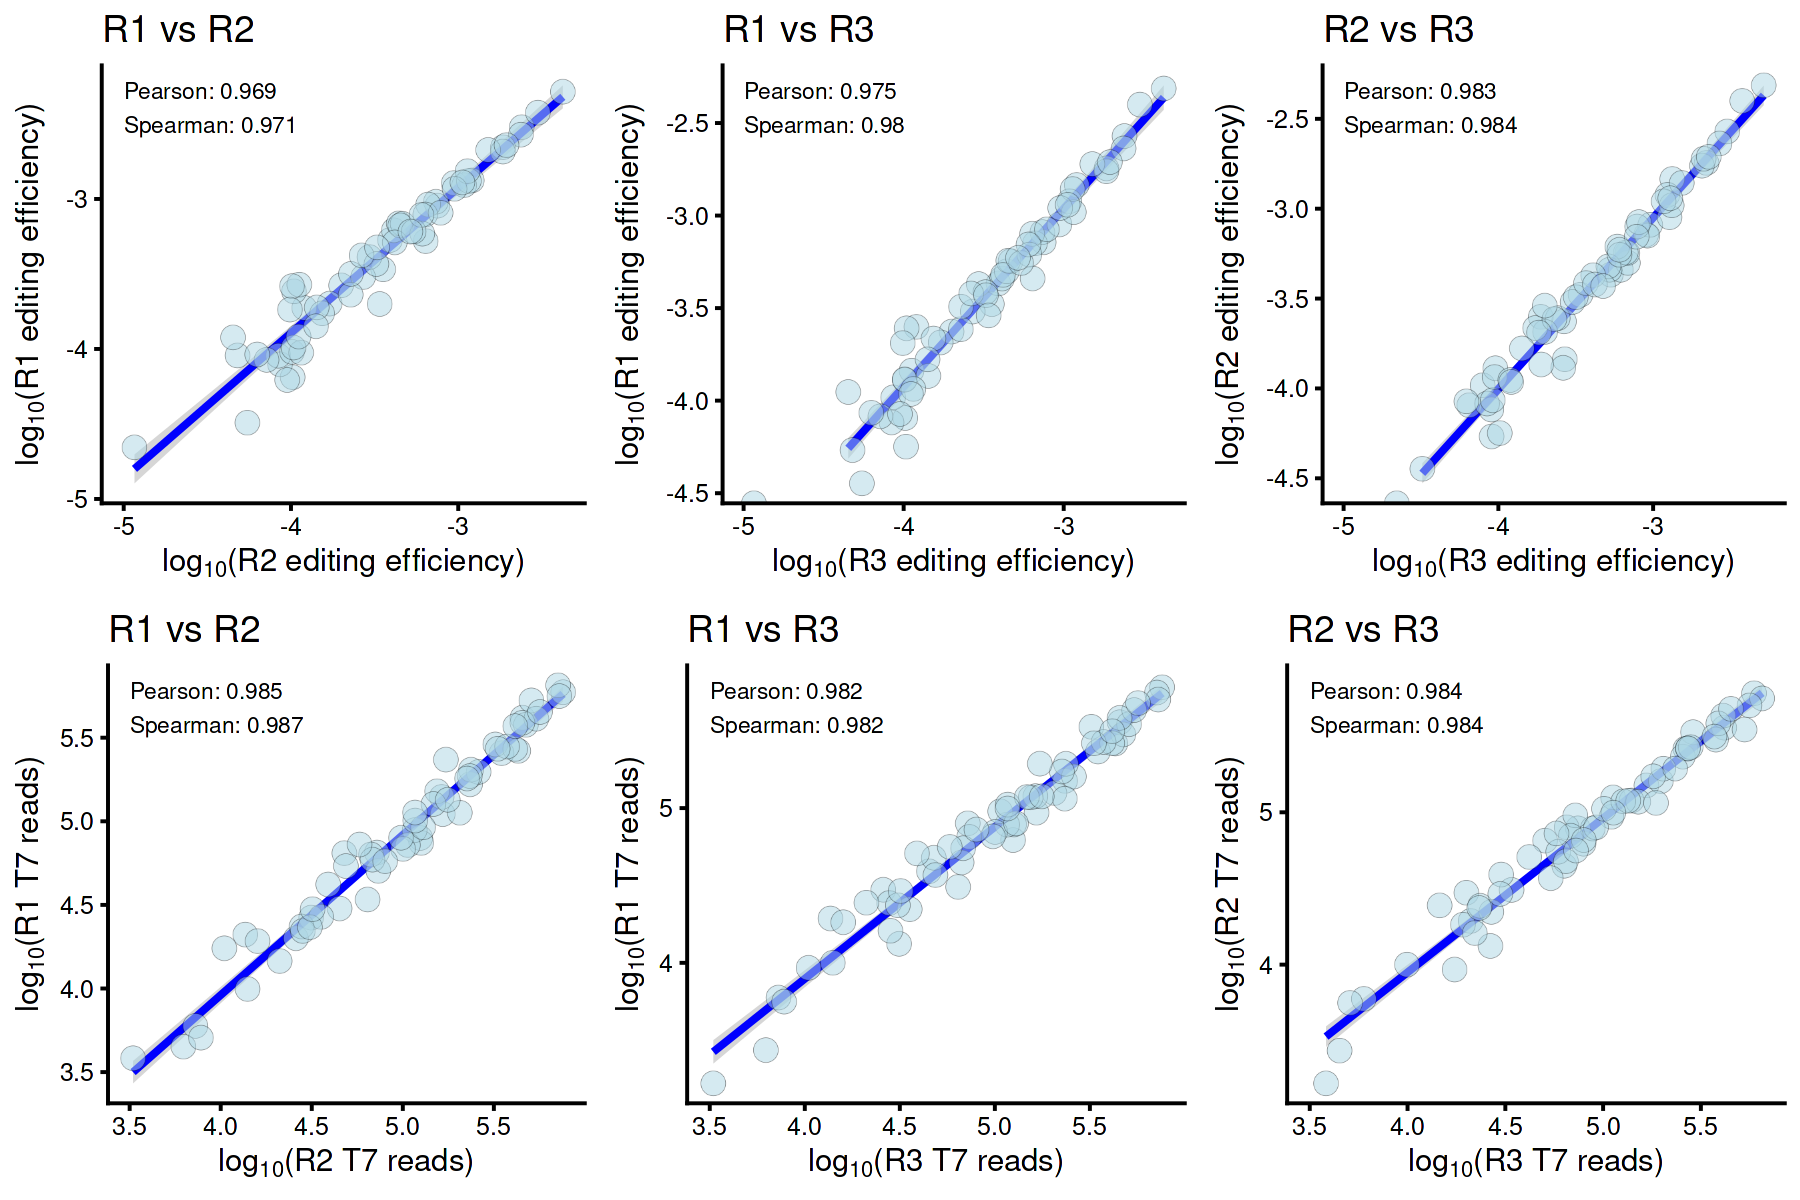

In [44]:
options(repr.plot.width=9, repr.plot.height=6, repr.plot.res=200)

fig <- ggarrange(compare_rep(edit_R1,edit_R2,"R1","R2"),
          compare_rep(edit_R1,edit_R3,"R1","R3"),
          compare_rep(edit_R2,edit_R3,"R2","R3"),
          
          compare_rep_t7(r1_edits,r2_edits,"R1","R2"),
          compare_rep_t7(r1_edits,r3_edits,"R1","R3"),
          compare_rep_t7(r2_edits,r3_edits,"R2","R3"),ncol=3,nrow=2)

fig

In [45]:
sessionInfo()

R version 4.3.2 (2023-10-31)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 22.04.4 LTS

Matrix products: default
BLAS:   /net/gs/vol3/software/modules-sw/R/4.3.2/Linux/Ubuntu22.04/x86_64/lib/R/lib/libRblas.so 
LAPACK: /net/gs/vol3/software/modules-sw/R/4.3.2/Linux/Ubuntu22.04/x86_64/lib/R/lib/libRlapack.so;  LAPACK version 3.11.0

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

time zone: America/Los_Angeles
tzcode source: system (glibc)

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] reshape2_1.4.4                          
 [2] patchwork_1.3.2                         
 [3] biomaRt_2.58.2                          
 [4] ggra